In [1]:
# ---
# jupyter:
#   jupytext:
#     text_representation:
#       extension: .py
#       format_name: percent
#       format_version: '1.3'
#       jupytext_version: 1.19.4
#   kernelspec:
#     display_name: py3
#     language: python
#     name: py3
# ---

##### Selma Nezihoglu - 2390917
##### Abhaykumar Narendrakumar Monasara - S2188510

In [2]:
# Notebook-only compatibility setup: route a02_helper's backend request to static inline figures in Notebook 7.
from IPython import get_ipython
_ipython = get_ipython()
_original_run_line_magic = _ipython.run_line_magic

def _a02_inline_matplotlib_magic(name, line, *args, **kwargs):
    if name == "matplotlib":
        return _original_run_line_magic(name, "inline", *args, **kwargs)
    return _original_run_line_magic(name, line, *args, **kwargs)

_ipython.run_line_magic = _a02_inline_matplotlib_magic

In [3]:
import numpy as np
import matplotlib as plt

%load_ext autoreload
%autoreload 2

from a02_helper import *
from a02_functions import (
    sigma,
    logsigma,
    er,
    d_er,
    gd_er,
    sgdepoch_er,
    sgd_er,
    optimize,
)

In [4]:
# Restore IPython's normal magic handler after importing a02_helper.
_ipython.run_line_magic = _original_run_line_magic
_ipython.run_line_magic("matplotlib", "inline")

# 2. Empirical Risk Minimization

## Helper functions

Define the logistic function in `a02_functions.py`. Make sure it operates on both
scalars and vectors. Then test it below.

In [5]:
# this should give:
# [0.5, array([0.26894142, 0.5, 0.73105858])]
[sigma(0), sigma(np.array([-1, 0, 1]))]

[np.float64(0.5), array([0.26894142, 0.5       , 0.73105858])]

Define the logarithm of the logistic function in `a02_functions.py`. Make sure it
operates on both scalars and vectors.

In [6]:
# this should give:
# [-0.69314718055994529, array([-1.31326169, -0.69314718, -0.31326169])]
[logsigma(0), logsigma(np.array([-1, 0, 1]))]

[np.float64(-0.6931471805599453),
 array([-1.31326169, -0.69314718, -0.31326169])]

## 2b Empirical risk and gradient

Complete the function for the empirical risk of the logistic regression model in
`a02_functions.py` and test it below.

In [7]:
# this should give:
# 15.356163676288993
er(y, Xz, np.linspace(-5, 5, D))

np.float64(15.356163676288997)

Now fill out the function that returns the gradient of the empirical risk of the
logistic regression model in `a02_functions.py`, and test it below.

In [8]:
# this should give:
# array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
#        -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
#        -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
#        -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
#        -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
#         0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
#         0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
#         0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
#         0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
#         0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
#         0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
#        -0.12338248, -0.1357652 ])
d_er(y, Xz, np.linspace(-5, 5, D))

array([-0.1798825 , -0.04693023, -0.27466027, -0.05118185, -0.26186368,
       -0.25969397, -0.3003884 , -0.20292501, -0.21506925, -0.15360933,
       -0.25165549, -0.11497659, -0.14866875, -0.07646526, -0.18350882,
       -0.28216633, -0.25683434, -0.21190226, -0.29450173, -0.17748953,
       -0.38329083, -0.03926913, -0.27393521, -0.20662464,  0.23056057,
        0.20561304,  0.18575698,  0.17210766,  0.11730408,  0.1555117 ,
        0.1342924 ,  0.12238809,  0.11268253,  0.12274729,  0.13289319,
        0.14885237,  0.19473723,  0.03522699,  0.12881622,  0.07477366,
        0.09411536,  0.11815139,  0.1471057 ,  0.09038803,  0.13539737,
        0.14756532,  0.05466443,  0.08838642,  0.08228431,  0.11671288,
        0.08454313, -0.13649572, -0.19724037, -0.01406327, -0.04967132,
       -0.12338248, -0.1357652 ])

## 2c Gradient descent

In `a02_functions.py`, define the objective and update function for one
gradient-descent epoch for fitting an MLE estimate of logistic regression with
gradient descent (should return a tuple of two functions; see `optimize` in
`a02_functions.py`). Then test it below.

In [9]:
# this should give
# [15.356163676288993,
#  array([-4.98486859, -5.00348273, -4.97957969, -4.99464192, -4.98028549,
#         -4.97881798, -4.97516411, -4.98255264, -4.97950841, -4.98353035,
#         -4.97505258, -4.99343004, -4.98739394, -4.991352  , -4.97951014,
#         -4.97641948, -4.97550312, -4.98109859, -4.97826941, -4.98042354,
#         -4.96918027, -4.98940344, -4.97057868, -4.980086  , -5.00671666,
#         -5.00338624, -5.01360572, -4.9991855 , -4.99962596, -4.9990924 ,
#         -4.99728516, -4.99710625, -5.00490407, -4.99711359, -4.99844041,
#         -4.99879209, -5.00255707, -4.99927668, -5.00020121, -4.99270287,
#         -5.00059118, -5.00229197, -4.9975015 , -5.00292195, -5.00493102,
#         -5.00724744, -4.99867731, -5.00170438, -4.99836863, -4.99853799,
#         -4.9994118 , -4.98326416, -4.97266254, -4.99221473, -4.98906378,
#         -4.98190217, -4.97744729])]
f, update = gd_er(y, Xz)
[f(np.linspace(-5, 5, D)), update(np.linspace(-5, -5, D), 0.1)]

[np.float64(15.356163676288997),
 array([-4.98486859, -5.00348273, -4.97957969, -4.99464192, -4.98028549,
        -4.97881798, -4.97516411, -4.98255264, -4.97950841, -4.98353035,
        -4.97505258, -4.99343004, -4.98739394, -4.991352  , -4.97951014,
        -4.97641948, -4.97550312, -4.98109859, -4.97826941, -4.98042354,
        -4.96918027, -4.98940344, -4.97057868, -4.980086  , -5.00671666,
        -5.00338624, -5.01360572, -4.9991855 , -4.99962596, -4.9990924 ,
        -4.99728516, -4.99710625, -5.00490407, -4.99711359, -4.99844041,
        -4.99879209, -5.00255707, -4.99927668, -5.00020121, -4.99270287,
        -5.00059118, -5.00229197, -4.9975015 , -5.00292195, -5.00493102,
        -5.00724744, -4.99867731, -5.00170438, -4.99836863, -4.99853799,
        -4.9994118 , -4.98326416, -4.97266254, -4.99221473, -4.98906378,
        -4.98190217, -4.97744729])]

In [10]:
# Now you can run gradient descent!
np.random.seed(0)
w0 = np.random.normal(size=D)
wz_gd, vz_gd, ez_gd = optimize(gd_er(y, Xz), w0, nepochs=500, verbose=False)

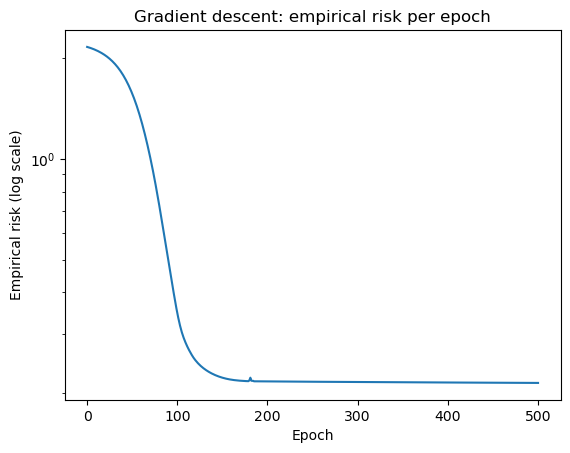

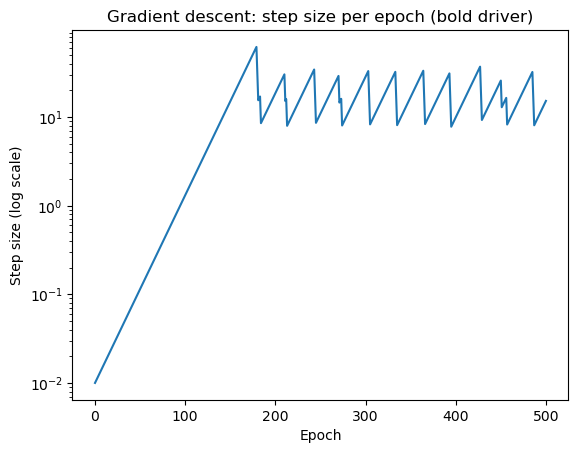

epoch   0: risk 2.1652, step size 0.01
epoch  10: risk 2.1165, step size 0.01629
epoch  50: risk 1.5697, step size 0.1147
epoch 100: risk 0.3466, step size 1.315
epoch 200: risk 0.2167, step size 18.67
epoch 300: risk 0.2158, step size 28.63
epoch 500: risk 0.2145, step size 15.26
epochs in which the risk went up (step size halved): 23
norm of the gradient at the end: 0.0005757343249670458


In [11]:
# look at how gradient descent made progess
# YOUR CODE HERE
# Empirical risk per epoch (log scale) and the step size chosen by the bold driver
nextplot()
plt.semilogy(vz_gd)
plt.xlabel("Epoch")
plt.ylabel("Empirical risk (log scale)")
plt.title("Gradient descent: empirical risk per epoch")
plt.show()

nextplot()
plt.semilogy(ez_gd)
plt.xlabel("Epoch")
plt.ylabel("Step size (log scale)")
plt.title("Gradient descent: step size per epoch (bold driver)")
plt.show()

for e in [0, 10, 50, 100, 200, 300, 500]:
    print(f"epoch {e:3d}: risk {vz_gd[e]:.4f}, step size {ez_gd[e]:.4g}")
print("epochs in which the risk went up (step size halved):", np.sum(np.diff(vz_gd) > 0))
print("norm of the gradient at the end:", np.linalg.norm(d_er(y, Xz, wz_gd)))

## 2d Stochastic gradient descent

Implement stochastic gradient descent in `a02_functions.py`. Then test it with the
given results below.

In [12]:
# when you run this multiple times, with 50% probability you should get the
# following result (there is one other result which is very close):
# array([ -3.43689655e+02,  -1.71161311e+02,  -5.71093536e+02,
#         -5.16478220e+01,   4.66294348e+02,  -3.71589878e+02,
#          5.21493183e+02,   1.25699230e+03,   8.33804130e+02,
#          5.63185399e+02,   1.32761302e+03,  -2.64104011e+02,
#          7.10693307e+02,  -1.75497331e+02,  -1.94174427e+02,
#          1.11641507e+02,  -3.30817509e+02,  -3.46754913e+02,
#          8.48722111e+02,  -1.89136304e+02,  -4.25693844e+02,
#         -1.23084189e+02,  -2.95894797e+02,  -2.35789333e+02,
#         -3.38695243e+02,  -3.05642830e+02,  -2.28975383e+02,
#         -2.38075137e+02,  -1.66702530e+02,  -2.27341599e+02,
#         -1.77575620e+02,  -1.49093855e+02,  -1.70028859e+02,
#         -1.50243833e+02,  -1.82986008e+02,  -2.41143708e+02,
#         -3.31047159e+02,  -5.79991185e+01,  -1.98477863e+02,
#         -1.91264948e+02,  -1.17371919e+02,  -1.66953779e+02,
#         -2.01472565e+02,  -1.23330949e+02,  -3.00857740e+02,
#         -1.95853348e+02,  -7.44868073e+01,  -1.11172370e+02,
#         -1.57618226e+02,  -1.25729512e+00,  -1.45536466e+02,
#         -1.43362438e+02,  -3.00429708e+02,  -9.84391082e+01,
#         -4.54152047e+01,  -5.26492232e+01,  -1.45175427e+02])
sgdepoch_er(y[1:3], Xz[1:3, :], np.linspace(-5, 5, D), 1000)

array([-3.43689655e+02, -1.71161311e+02, -5.71093536e+02, -5.16478220e+01,
        4.66294348e+02, -3.71589878e+02,  5.21493183e+02,  1.25699230e+03,
        8.33804130e+02,  5.63185399e+02,  1.32761302e+03, -2.64104011e+02,
        7.10693307e+02, -1.75497331e+02, -1.94174427e+02,  1.11641507e+02,
       -3.30817509e+02, -3.46754913e+02,  8.48722111e+02, -1.89136304e+02,
       -4.25693844e+02, -1.23084189e+02, -2.95894797e+02, -2.35789333e+02,
       -3.38695243e+02, -3.05642830e+02, -2.28975383e+02, -2.38075137e+02,
       -1.66702530e+02, -2.27341599e+02, -1.77575620e+02, -1.49093855e+02,
       -1.70028859e+02, -1.50243833e+02, -1.82986008e+02, -2.41143708e+02,
       -3.31047159e+02, -5.79991185e+01, -1.98477863e+02, -1.91264948e+02,
       -1.17371919e+02, -1.66953779e+02, -2.01472565e+02, -1.23330949e+02,
       -3.00857740e+02, -1.95853348e+02, -7.44868073e+01, -1.11172370e+02,
       -1.57618226e+02, -1.25729512e+00, -1.45536466e+02, -1.43362438e+02,
       -3.00429708e+02, -

In [13]:
# with 50% probability, you should get:
# [20.43248652284754,
#  array([ -3.43689655e+02,  -1.71161311e+02,  -5.71093536e+02,
#          -5.16478220e+01,   4.66294348e+02,  -3.71589878e+02,
#           5.21493183e+02,   1.25699230e+03,   8.33804130e+02,
#           5.63185399e+02,   1.32761302e+03,  -2.64104011e+02,
#           7.10693307e+02,  -1.75497331e+02,  -1.94174427e+02,
#           1.11641507e+02,  -3.30817509e+02,  -3.46754913e+02,
#           8.48722111e+02,  -1.89136304e+02,  -4.25693844e+02,
#          -1.23084189e+02,  -2.95894797e+02,  -2.35789333e+02,
#          -3.38695243e+02,  -3.05642830e+02,  -2.28975383e+02,
#          -2.38075137e+02,  -1.66702530e+02,  -2.27341599e+02,
#          -1.77575620e+02,  -1.49093855e+02,  -1.70028859e+02,
#          -1.50243833e+02,  -1.82986008e+02,  -2.41143708e+02,
#          -3.31047159e+02,  -5.79991185e+01,  -1.98477863e+02,
#          -1.91264948e+02,  -1.17371919e+02,  -1.66953779e+02,
#          -2.01472565e+02,  -1.23330949e+02,  -3.00857740e+02,
#          -1.95853348e+02,  -7.44868073e+01,  -1.11172370e+02,
#          -1.57618226e+02,  -1.25729512e+00,  -1.45536466e+02,
#          -1.43362438e+02,  -3.00429708e+02,  -9.84391082e+01,
#          -4.54152047e+01,  -5.26492232e+01,  -1.45175427e+02])]
f, update = sgd_er(y[1:3], Xz[1:3, :])
[f(np.linspace(-5, 5, D)), update(np.linspace(-5, 5, D), 1000)]

[np.float64(20.432486522847544),
 array([-3.43689655e+02, -1.71161311e+02, -5.71093536e+02, -5.16478220e+01,
         4.66294348e+02, -3.71589878e+02,  5.21493183e+02,  1.25699230e+03,
         8.33804130e+02,  5.63185399e+02,  1.32761302e+03, -2.64104011e+02,
         7.10693307e+02, -1.75497331e+02, -1.94174427e+02,  1.11641507e+02,
        -3.30817509e+02, -3.46754913e+02,  8.48722111e+02, -1.89136304e+02,
        -4.25693844e+02, -1.23084189e+02, -2.95894797e+02, -2.35789333e+02,
        -3.38695243e+02, -3.05642830e+02, -2.28975383e+02, -2.38075137e+02,
        -1.66702530e+02, -2.27341599e+02, -1.77575620e+02, -1.49093855e+02,
        -1.70028859e+02, -1.50243833e+02, -1.82986008e+02, -2.41143708e+02,
        -3.31047159e+02, -5.79991185e+01, -1.98477863e+02, -1.91264948e+02,
        -1.17371919e+02, -1.66953779e+02, -2.01472565e+02, -1.23330949e+02,
        -3.00857740e+02, -1.95853348e+02, -7.44868073e+01, -1.11172370e+02,
        -1.57618226e+02, -1.25729512e+00, -1.45536466e+

In [14]:
# you can run stochastic gradient descent!
wz_sgd, vz_sgd, ez_sgd = optimize(sgd_er(y, Xz), w0, nepochs=500, verbose=False)

## 2e Compare GD and SGD

Explore the behavior of both methods, given the parameters provided to you!

estimated minimum of the empirical risk R* = 0.20475
time per epoch: GD 0.09 ms, SGD 5.1 ms (57x)


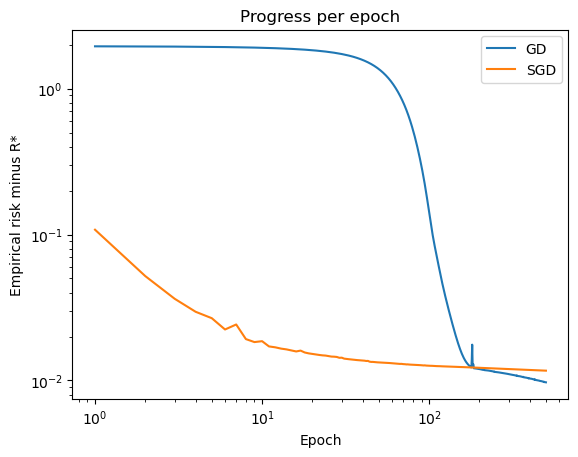

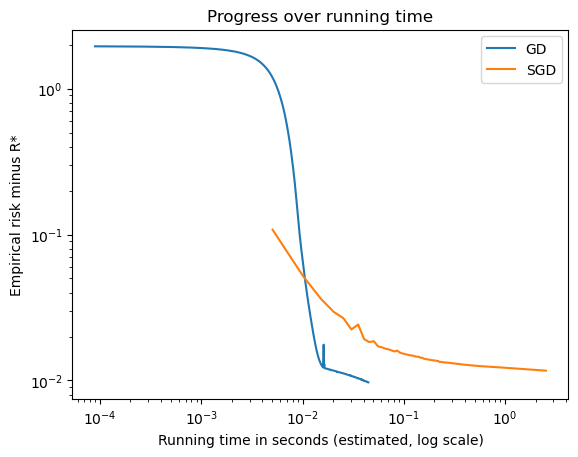

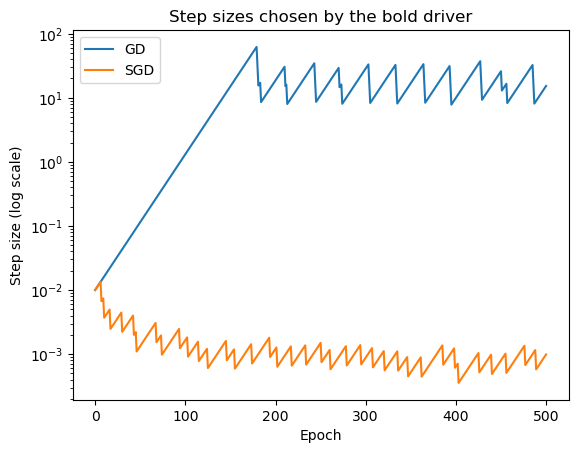

                   final risk  epoch risk <= 1.10 R*  epoch risk <= 1.05 R*  train accuracy  test accuracy  test log loss  norm of w  steps halved
GD (500 epochs)        0.2145                  144.0                  414.0          0.9217         0.9186         0.2792     8.9448          23.0
SGD (500 epochs)       0.2164                    8.0                    NaN          0.9214         0.9173         0.2827     6.7603          36.0
GD (30000 epochs)      0.2048                    NaN                    NaN          0.9233         0.9271         0.2698    50.0984           NaN


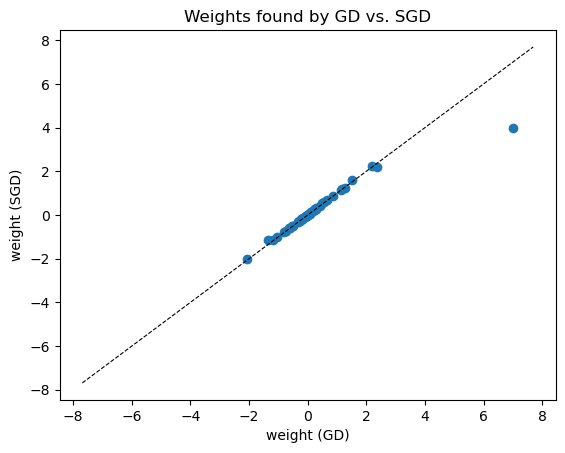

correlation of the weight vectors: 0.9619
SGD seed 1: risk after 1 epoch 0.3203, after 500 epochs 0.21639, final step size 0.00099
SGD seed 2: risk after 1 epoch 0.3212, after 500 epochs 0.21638, final step size 0.00099
SGD seed 3: risk after 1 epoch 0.3142, after 500 epochs 0.21642, final step size 0.00099


SGD seed 1: risk after 1 epoch 0.3203, after 500 epochs 0.21639, final step size 0.00099


SGD seed 2: risk after 1 epoch 0.3212, after 500 epochs 0.21638, final step size 0.00099


SGD seed 3: risk after 1 epoch 0.3142, after 500 epochs 0.21642, final step size 0.00099


In [15]:
# YOUR CODE HERE
import time

# Reference point: run GD for many more epochs to estimate the minimal empirical risk R*
# (about 3 seconds; sklearn's LogisticRegression without penalty and bias gives the same value)
wz_ref, vz_ref, _ = optimize(gd_er(y, Xz), w0, nepochs=30000, verbose=False)
r_star = vz_ref[-1]
print(f"estimated minimum of the empirical risk R* = {r_star:.5f}")

# Cost of one epoch: GD computes one full gradient, SGD performs N single-example updates
f_gd, upd_gd = gd_er(y, Xz)
f_sgd, upd_sgd = sgd_er(y, Xz)
t = time.perf_counter()
[upd_gd(w0, 0.01) for _ in range(50)]
t_gd = (time.perf_counter() - t) / 50
t = time.perf_counter()
[upd_sgd(w0, 0.01) for _ in range(5)]
t_sgd = (time.perf_counter() - t) / 5
print(f"time per epoch: GD {1000 * t_gd:.2f} ms, SGD {1000 * t_sgd:.1f} ms ({t_sgd / t_gd:.0f}x)")

# 1) Risk per epoch (distance to R*, log-log scale to see the early phase as well)
epochs = np.arange(1, len(vz_gd))
nextplot()
plt.loglog(epochs, vz_gd[1:] - r_star, label="GD")
plt.loglog(epochs, vz_sgd[1:] - r_star, label="SGD")
plt.xlabel("Epoch")
plt.ylabel("Empirical risk minus R*")
plt.title("Progress per epoch")
plt.legend()
plt.show()

# 2) Risk over (estimated) running time
nextplot()
plt.loglog(epochs * t_gd, vz_gd[1:] - r_star, label="GD")
plt.loglog(epochs * t_sgd, vz_sgd[1:] - r_star, label="SGD")
plt.xlabel("Running time in seconds (estimated, log scale)")
plt.ylabel("Empirical risk minus R*")
plt.title("Progress over running time")
plt.legend()
plt.show()

# 3) Step sizes chosen by the bold driver
nextplot()
plt.semilogy(ez_gd, label="GD")
plt.semilogy(ez_sgd, label="SGD")
plt.xlabel("Epoch")
plt.ylabel("Step size (log scale)")
plt.title("Step sizes chosen by the bold driver")
plt.legend()
plt.show()

# 4) Summary of the fitted models
def accuracy(Xs, ys, w):
    return np.mean((Xs @ w > 0) == ys)


def first_epoch_within(v, tol):
    """First epoch with risk at most (1 + tol) * R*, or None."""
    idx = np.where(v <= (1 + tol) * r_star)[0]
    return int(idx[0]) if len(idx) > 0 else None


summary = pd.DataFrame(
    {
        "final risk": [vz_gd[-1], vz_sgd[-1], r_star],
        "epoch risk <= 1.10 R*": [first_epoch_within(vz_gd, 0.10), first_epoch_within(vz_sgd, 0.10), None],
        "epoch risk <= 1.05 R*": [first_epoch_within(vz_gd, 0.05), first_epoch_within(vz_sgd, 0.05), None],
        "train accuracy": [accuracy(Xz, y, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "test accuracy": [accuracy(Xtestz, ytest, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "test log loss": [er(ytest, Xtestz, w) for w in [wz_gd, wz_sgd, wz_ref]],
        "norm of w": [np.linalg.norm(w) for w in [wz_gd, wz_sgd, wz_ref]],
        "steps halved": [np.sum(np.diff(vz_gd) > 0), np.sum(np.diff(vz_sgd) > 0), None],
    },
    index=["GD (500 epochs)", "SGD (500 epochs)", "GD (30000 epochs)"],
)
print(summary.round(4).to_string())

# 5) Do both methods find the same weights?
nextplot()
plt.scatter(wz_gd, wz_sgd)
lim = np.abs(np.concatenate([wz_gd, wz_sgd])).max() * 1.1
plt.plot([-lim, lim], [-lim, lim], "k--", linewidth=0.8)
plt.xlabel("weight (GD)")
plt.ylabel("weight (SGD)")
plt.title("Weights found by GD vs. SGD")
plt.show()
print("correlation of the weight vectors:", np.corrcoef(wz_gd, wz_sgd)[0, 1].round(4))

# 6) SGD is random: repeat it with different seeds
for seed in [1, 2, 3]:
    np.random.seed(seed)
    _, v, e = optimize(sgd_er(y, Xz), w0, nepochs=500, verbose=False)
    print(f"SGD seed {seed}: risk after 1 epoch {v[1]:.4f}, after 500 epochs {v[-1]:.5f}, final step size {e[-1]:.2g}")